# Progress report figures (slides 5-7)

Charts of the lookup table for the progress-report presentation. Reads
`results/lookup_table/lookup_table.csv` and writes PNGs to `results/figures/`.

**Only the lookup table is used here; no GA or random-search runs.** The random-search
numbers are exact expectations over the 570 scored configs (random search
evaluates `n` unique configs, which is the same as sampling without replacement).

The figures use the slide deck's slate background so they can go straight onto
the slides.

In [1]:
from math import comb
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

lt = pd.read_csv(ROOT / "results" / "lookup_table" / "lookup_table.csv")
exp = yaml.safe_load((ROOT / "config" / "experiment.yaml").read_text())
N = len(lt)
BUDGETS = [int(f * N) for f in exp["budgets"]]  # rounded down, as SearchSpace.budget
BEST = lt.tuning_ndcg.max()
print(f"{N} configs, budgets {BUDGETS}, best tuning nDCG@5 = {BEST:.4f}")

570 configs, budgets [28, 57, 114], best tuning nDCG@5 = 0.5168


## Style

The colors match the deck: a slate background (`#37474F`), white and light-gray text,
and a Georgia serif close to the deck's body font. The series colors are checked
against the slate with the dataviz palette validator (all pairs):

| Role | Hex | Contrast on slate |
|---|---|---|
| Series 1 (blue) | `#6da7ec` | ≥ 3:1 |
| Series 2 (orange) | `#eb6834` | ≥ 3:1 |
| Series 3 (aqua) | `#1baf7a` | ≥ 3:1 |

Worst color-blind ΔE across all pairs is 9.2 and the normal-vision floor is 19.2, so both pass.
The palette sits slightly above the validator's dark-mode lightness band, because slate is
lighter than a typical dark surface and the marks need the extra lightness to keep 3:1
contrast. Every series is also labeled directly.

In [2]:
BG = "#37474F"
TEXT = "#FFFFFF"
TEXT2 = "#CFD8DC"   # secondary text, axis labels
MUTED = "#90A4AE"   # tick labels
GRID = "#4E5F68"    # recessive gridlines / axes
BLUE, ORANGE, AQUA = "#6da7ec", "#eb6834", "#1baf7a"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "font.family": "Georgia", "font.size": 13,
    "text.color": TEXT, "axes.labelcolor": TEXT2, "axes.edgecolor": GRID,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": MUTED, "ytick.labelcolor": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 15, "axes.titlecolor": TEXT, "axes.titlelocation": "left",
    "legend.frameon": False, "legend.labelcolor": TEXT2,
    "lines.linewidth": 2.2, "lines.solid_capstyle": "round",
})

def save(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", pad_inches=0.25)
    print("saved", path.relative_to(ROOT))

## Slide 5: the landscape

A histogram of tuning nDCG@5 across all 570 valid configs. The bins are 0.005 wide and
anchored at the best score, so the two orange bins hold exactly the configs within 0.01 of the
optimum.

saved results\figures\slide5_landscape.png


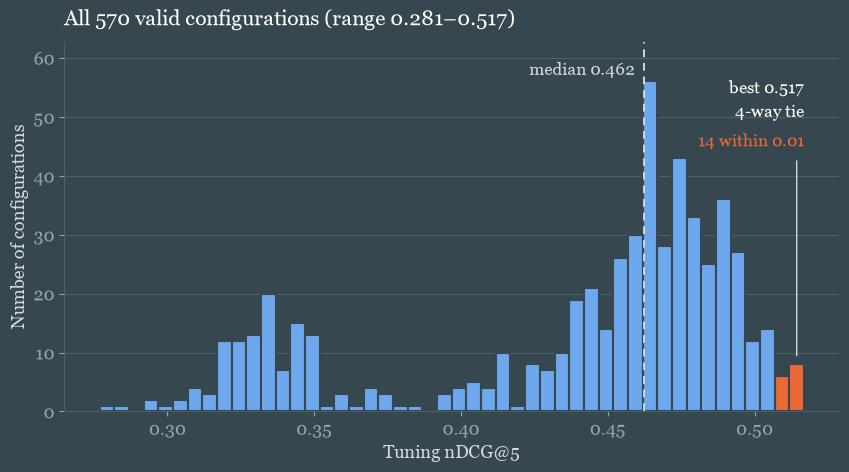

In [3]:
WIDTH = 0.005
edges = np.sort(BEST + 1e-9 - WIDTH * np.arange(0, int((BEST - lt.tuning_ndcg.min()) / WIDTH) + 2))
counts, _ = np.histogram(lt.tuning_ndcg, bins=edges)
near = edges[:-1] >= BEST - 0.01 - 1e-9
n_near = int((lt.tuning_ndcg >= BEST - 0.01).sum())
n_tie = int((lt.tuning_ndcg == BEST).sum())
median = lt.tuning_ndcg.median()
assert counts[near].sum() == n_near

fig, ax = plt.subplots(figsize=(10, 4.8))
ax.bar(edges[:-1], counts, width=WIDTH, align="edge",
       color=np.where(near, ORANGE, BLUE), edgecolor=BG, linewidth=1.5)
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
ax.set_xlabel("Tuning nDCG@5")
ax.set_ylabel("Number of configurations")

ax.axvline(median, color=TEXT2, linestyle=(0, (4, 3)), linewidth=1.4)
ax.text(median - 0.003, counts.max() * 1.02, f"median {median:.3f}", ha="right", color=TEXT2, fontsize=12)
ax.annotate("", xy=(BEST - WIDTH / 2, counts[-1] + 1), xytext=(BEST - WIDTH / 2, 43),
            arrowprops=dict(arrowstyle="-", color=TEXT2, lw=1))
ax.text(BEST, 54, f"best {BEST:.3f}", ha="right", color=TEXT, fontsize=12)
ax.text(BEST, 50, f"{n_tie}-way tie", ha="right", color=TEXT, fontsize=12)
ax.text(BEST, 45, f"{n_near} within 0.01", ha="right", color=ORANGE, fontsize=12)
ax.set_title(f"All {N} valid configurations (range {lt.tuning_ndcg.min():.3f}–{BEST:.3f})", pad=12)
ax.set_ylim(0, counts.max() * 1.12)
save(fig, "slide5_landscape")
plt.show()

## Slide 6a: mean score by gene value

Each point is the mean tuning nDCG@5 over every valid config with that gene value (a main
effect). The marginals are over **valid** configs only, so the overlap = 128 mean has no chunk
size 128 configs in it (overlap must be smaller than chunk size). Read the overlap panel with
that in mind. Dots are used instead of bars because the y-axis does not start at zero.

saved results\figures\slide6_gene_means.png


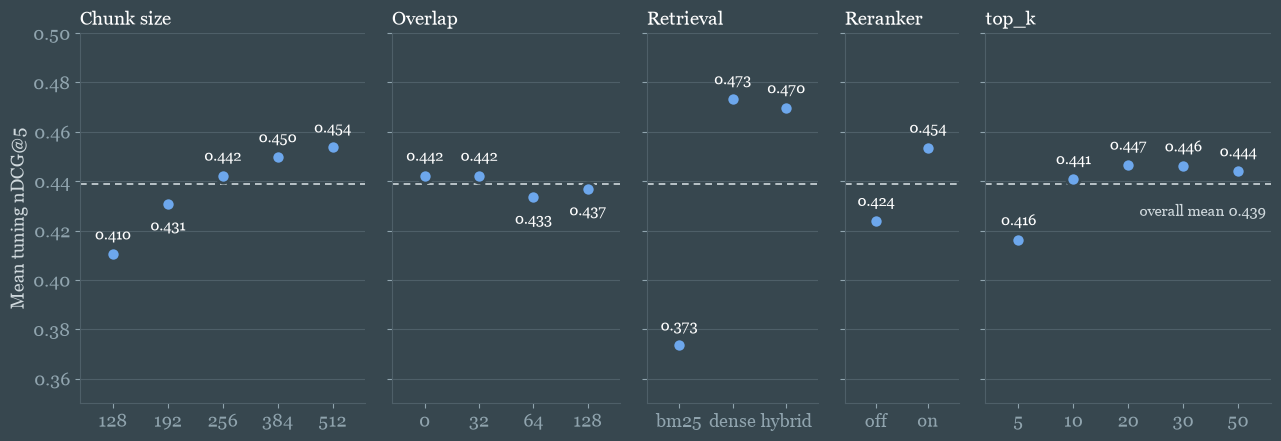

In [4]:
genes = [("chunk_size", "Chunk size"), ("chunk_overlap", "Overlap"), ("retrieval_type", "Retrieval"),
         ("reranker", "Reranker"), ("top_k", "top_k")]
overall = lt.tuning_ndcg.mean()

fig, axes = plt.subplots(1, len(genes), figsize=(13, 4.6), sharey=True,
                         gridspec_kw={"width_ratios": [5, 4, 3, 2, 5]})
for ax, (col, label) in zip(axes, genes):
    m = lt.groupby(col, sort=True).tuning_ndcg.mean()
    names = [("on" if v else "off") if col == "reranker" else str(v) for v in m.index]
    x = np.arange(len(m))
    ax.axhline(overall, color=TEXT2, linestyle=(0, (4, 3)), linewidth=1.2)
    ax.scatter(x, m.values, s=90, color=BLUE, edgecolor=BG, linewidth=2, zorder=3)
    for xi, v in zip(x, m.values):
        below = v < overall < v + 0.013  # label above would sit on the mean line
        ax.text(xi, v - 0.006 if below else v + 0.006, f"{v:.3f}", ha="center",
                va="top" if below else "baseline", color=TEXT, fontsize=11)
    ax.set_xticks(x, names)
    ax.set_xlim(-0.6, len(m) - 0.4)
    ax.set_title(label, fontsize=14)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Mean tuning nDCG@5")
axes[0].set_ylim(0.35, 0.50)
axes[-1].text(len(axes[-1].get_xticks()) - 0.5, overall - 0.008, f"overall mean {overall:.3f}",
              ha="right", va="top", color=TEXT2, fontsize=11)
fig.tight_layout(w_pad=1.2)
save(fig, "slide6_gene_means")
plt.show()

## Slide 6b: where the reranker helps

The change in mean tuning nDCG@5 from turning the reranker on, by chunk size, for each
retrieval type (averaged over overlap and top_k). The reranker lifts BM25 at every chunk size.
For dense it is roughly neutral overall: it helps at 192 and 256 and **hurts at 512**, where
about 46% of (question, chunk) pairs exceed MiniLM's 512-token limit and get truncated.

retrieval_type   bm25  dense  hybrid
chunk_size                          
128             0.057 -0.001   0.012
192             0.087  0.015   0.021
256             0.092  0.013   0.006
384             0.090  0.000   0.005
512             0.089 -0.025  -0.023
saved results\figures\slide6_reranker_effect.png


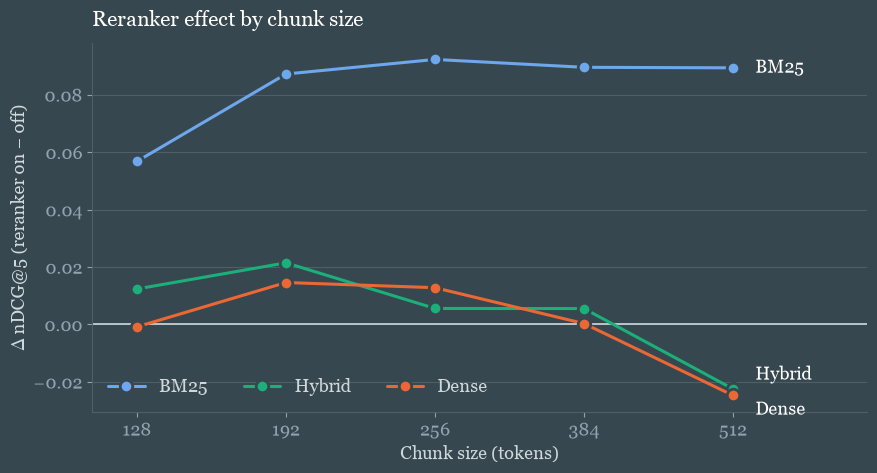

In [5]:
piv = lt.pivot_table(index=["retrieval_type", "chunk_size"], columns="reranker", values="tuning_ndcg")
delta = (piv[True] - piv[False]).unstack("retrieval_type")
print(delta.round(3))

fig, ax = plt.subplots(figsize=(10, 4.8))
x = np.arange(len(delta))
ax.axhline(0, color=TEXT2, linewidth=1.2)
for col, color, name, dy in [("bm25", BLUE, "BM25", 0), ("hybrid", AQUA, "Hybrid", 0.005),
                             ("dense", ORANGE, "Dense", -0.005)]:
    ax.plot(x, delta[col], color=color, marker="o", markersize=9, markeredgecolor=BG, markeredgewidth=2, label=name)
    ax.text(x[-1] + 0.15, delta[col].iloc[-1] + dy, name, color=TEXT, va="center", fontsize=13)
ax.set_xticks(x, [str(c) for c in delta.index])
ax.set_xlim(-0.3, len(x) - 0.1)
ax.set_xlabel("Chunk size (tokens)")
ax.set_ylabel("Δ nDCG@5 (reranker on − off)")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower left", ncols=3)
ax.set_title("Reranker effect by chunk size", pad=12)
save(fig, "slide6_reranker_effect")
plt.show()

## Slide 7a: the random-search baseline (exact)

Random search draws `n` unique configs uniformly from the 570 valid ones. If `m` configs reach
a threshold, then P(best found reaches it) = 1 − C(N−m, n) / C(N, n). For the expected gap,
sort the scores best-first. The best of the `n` draws is the config at rank i with probability
C(N−i, n−1) / C(N, n).

In [6]:
def p_hit(m, n, N=N):
    # P(a uniform n-subset contains at least one of m marked configs)
    return 1 - comb(N - m, n) / comb(N, n)

v = np.sort(lt.tuning_ndcg.values)[::-1]
gaps = BEST - v

def best_dist(n, N=N):
    # P(best of n draws is the config at sorted rank i), i = 1..N
    return np.array([comb(N - i, n - 1) for i in range(1, N + 1)], dtype=float) / comb(N, n)

m_opt = int((v == BEST).sum())
m_01 = int((gaps <= 0.01).sum())
rows = []
for n in BUDGETS:
    p = best_dist(n)
    cdf = np.cumsum(p)
    rows.append({"budget": n, "share": f"{n / N:.0%}",
                 "E[gap]": (p * gaps).sum(), "median gap": gaps[np.searchsorted(cdf, 0.5)],
                 "P(find optimum)": p_hit(m_opt, n), "P(within 0.01)": p_hit(m_01, n)})
baseline = pd.DataFrame(rows)
baseline.round(4)

,budget,share,E[gap],median gap,P(find optimum),P(within 0.01)
0,28,5%,0.0098,0.0096,0.1829,0.5101
1,57,10%,0.0052,0.0034,0.3447,0.7753
2,114,20%,0.0021,0.0000,0.5915,0.9578


saved results\figures\slide7_random_baseline.png


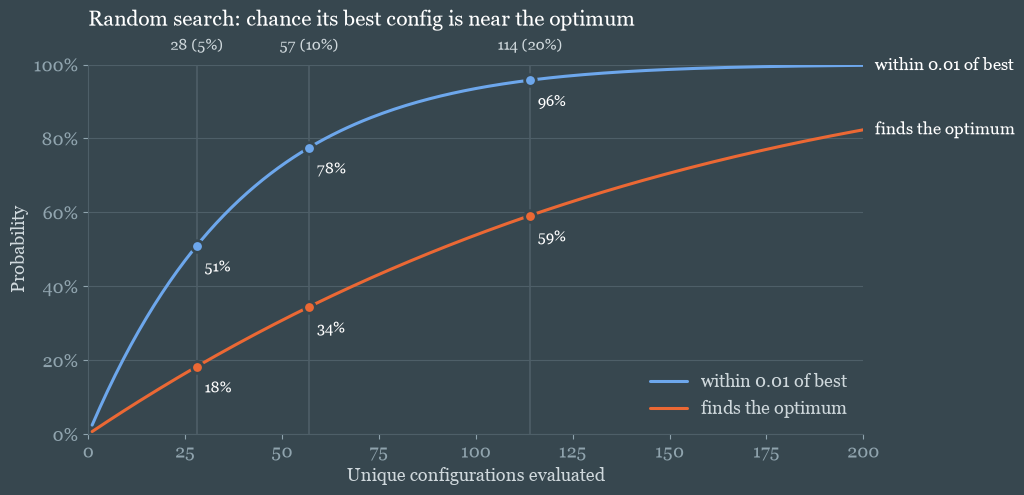

In [7]:
ns = np.arange(1, 201)
fig, ax = plt.subplots(figsize=(10, 4.8))
for m, color, name in [(m_01, BLUE, "within 0.01 of best"), (m_opt, ORANGE, "finds the optimum")]:
    ps = np.array([p_hit(m, n) for n in ns])
    ax.plot(ns, ps, color=color, label=name)
    ax.text(ns[-1] + 3, ps[-1], name, color=TEXT, va="center", fontsize=12)
    for n in BUDGETS:
        ax.scatter(n, p_hit(m, n), s=70, color=color, edgecolor=BG, linewidth=2, zorder=3)
        ax.text(n + 2, p_hit(m, n) - 0.07, f"{p_hit(m, n):.0%}", color=TEXT, fontsize=11)
for n, f in zip(BUDGETS, exp["budgets"]):
    ax.axvline(n, color=GRID, linewidth=1.2, zorder=0)
    ax.text(n, 1.04, f"{n} ({f:.0%})", ha="center", color=TEXT2, fontsize=11)
ax.set_xlim(0, ns[-1])
ax.set_ylim(0, 1.0)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("Unique configurations evaluated")
ax.set_ylabel("Probability")
ax.grid(axis="x", visible=False)
ax.legend(loc="lower right")
ax.set_title("Random search: chance its best config is near the optimum", pad=28)
save(fig, "slide7_random_baseline")
plt.show()

## Slide 7b: tuning vs. test

Each dot is one config. The dashed line is y = x. Tuning and test rankings agree
fairly well, but the configs tied for best on tuning are not the best on test.

                         key  tuning_ndcg  test_ndcg  test_rank
461  cs512_ov0_dense_rr0_k10     0.516847   0.493839         20
462  cs512_ov0_dense_rr0_k20     0.516847   0.493839         20
463  cs512_ov0_dense_rr0_k30     0.516847   0.493839         20
464  cs512_ov0_dense_rr0_k50     0.516847   0.493839         20
best on test: cs384_ov0_dense_rr1_k20 0.518
saved results\figures\slide7_tuning_vs_test.png


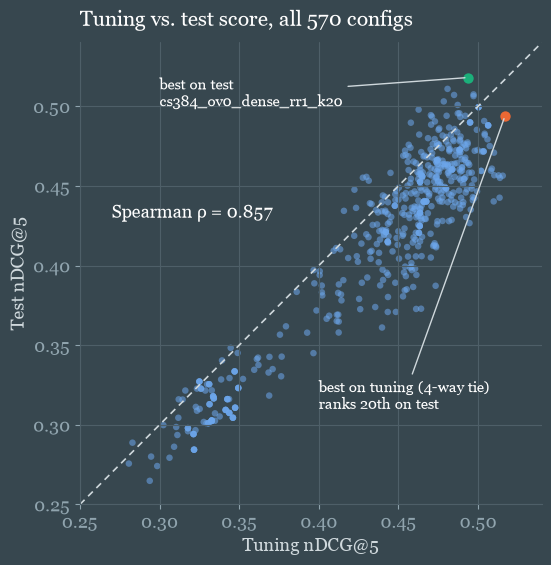

In [8]:
rho = lt.tuning_ndcg.corr(lt.test_ndcg, method="spearman")
lt["test_rank"] = lt.test_ndcg.rank(ascending=False, method="min").astype(int)
opt = lt[lt.tuning_ndcg == BEST]
best_test = lt.loc[lt.test_ndcg.idxmax()]
print(opt[["key", "tuning_ndcg", "test_ndcg", "test_rank"]])
print("best on test:", best_test.key, round(best_test.test_ndcg, 4))

fig, ax = plt.subplots(figsize=(7.5, 6))
lo, hi = 0.25, 0.54
ax.plot([lo, hi], [lo, hi], color=TEXT2, linestyle=(0, (4, 3)), linewidth=1.2)
ax.scatter(lt.tuning_ndcg, lt.test_ndcg, s=22, color=BLUE, alpha=0.55, edgecolor="none")
ax.scatter(opt.tuning_ndcg, opt.test_ndcg, s=90, color=ORANGE, edgecolor=BG, linewidth=2, zorder=3)
ax.scatter([best_test.tuning_ndcg], [best_test.test_ndcg], s=90, color=AQUA, edgecolor=BG, linewidth=2, zorder=3)
ax.annotate(f"best on tuning ({len(opt)}-way tie)\nranks {opt.test_rank.min()}th on test",
            xy=(opt.tuning_ndcg.iloc[0], opt.test_ndcg.iloc[0]), xytext=(0.40, 0.31),
            color=TEXT, fontsize=11, arrowprops=dict(arrowstyle="-", color=TEXT2, lw=1))
ax.annotate("best on test\n" + best_test.key, xy=(best_test.tuning_ndcg, best_test.test_ndcg),
            xytext=(0.30, 0.50), color=TEXT, fontsize=11, arrowprops=dict(arrowstyle="-", color=TEXT2, lw=1))
ax.text(0.27, 0.43, f"Spearman ρ = {rho:.3f}", color=TEXT, fontsize=13)
ax.set_xlim(lo, hi); ax.set_ylim(lo, hi)
ax.set_aspect("equal")
ax.set_xlabel("Tuning nDCG@5")
ax.set_ylabel("Test nDCG@5")
ax.set_title("Tuning vs. test score, all 570 configs", pad=12)
save(fig, "slide7_tuning_vs_test")
plt.show()